# Single-segment ablation of LEAF-1 token components, scATAC (Supplementary Figure 5)

Mean one-vs-all classification AUC across 10 cell types for classifiers trained on individual LEAF-1 segment embeddings (layer 4). Segments, in order: [CLS], [MOD], LEFT, CUT1, FRAG, CUT2, RIGHT. Error bars are BCa 95% CIs over the 10 cell-type AUCs.

Reads `../data/scatac_segment_sweep_auc.csv` (7 segments by 10 cell types) and writes the figure to `../output/`. Source: `scatac-dna-embedding-benchmark/benchmark/notebook/segment_window_sweep_leaf1.ipynb`.

In [1]:
from pathlib import Path
import sys

# Self-contained: works when run from this notebook's folder (nbconvert default),
# from the modality folder, or from the repo root.
nb_dir = Path.cwd()
if (nb_dir / "data").exists() and (nb_dir / "output").exists():
    MOD_DIR = nb_dir
elif (nb_dir.parent / "data").exists():
    MOD_DIR = nb_dir.parent
else:
    MOD_DIR = nb_dir
DATA = MOD_DIR / "data"
OUT = MOD_DIR / "output"
OUT.mkdir(exist_ok=True)

# Locate the shared style helper (src/leaf1figures) by walking up.
_p = nb_dir
while _p != _p.parent and not (_p / "src" / "leaf1figures").exists():
    _p = _p.parent
sys.path.insert(0, str(_p / "src"))

from leaf1figures.style import OKABE_ITO, savefig, set_paper_style
set_paper_style()
print("DATA:", DATA)
print("OUT :", OUT)


DATA: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/scatac/data
OUT : /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/scatac/output


  [CLS]  AUC=0.8682  [0.8206, 0.9125]
  [MOD]  AUC=0.8786  [0.8367, 0.9210]
  LEFT   AUC=0.8858  [0.8406, 0.9255]
  CUT1   AUC=0.8895  [0.8281, 0.9350]
  FRAG   AUC=0.9314  [0.8827, 0.9583]
  CUT2   AUC=0.8951  [0.8485, 0.9369]
  RIGHT  AUC=0.8913  [0.8407, 0.9291]
saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/scatac/output/scatac_segment_ablation.pdf
saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/scatac/output/scatac_segment_ablation.png
saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/scatac/output/scatac_segment_ablation.svg
saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/scatac/output/scatac_segment_ablation.tsv


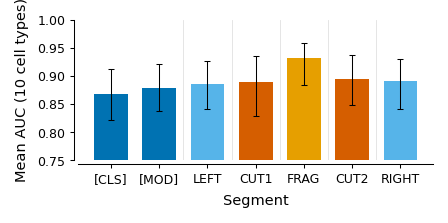

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats as sp_stats

# --- Load the staged per-cell-type, per-segment AUC table ---
df = pd.read_csv(DATA / 'scatac_segment_sweep_auc.csv')

segment_order  = ['cls', 'mod', 'left', 'cut1', 'fragment', 'cut2', 'right']
segment_labels = ['[CLS]', '[MOD]', 'LEFT', 'CUT1', 'FRAG', 'CUT2', 'RIGHT']
segment_groups = ['token', 'token', 'flank', 'cut', 'fragment', 'cut', 'flank']


def bca_ci_mean(vals, n_resamples=9999, seed=42):
    a = np.asarray(vals, dtype=float)
    res = sp_stats.bootstrap(
        (a,), np.mean, n_resamples=n_resamples,
        confidence_level=0.95, method='BCa',
        random_state=np.random.default_rng(seed),
    )
    return (float(np.mean(a)),
            float(res.confidence_interval.low),
            float(res.confidence_interval.high))


means, ci_lo, ci_hi = [], [], []
for seg in segment_order:
    vals = df.loc[df['segment'] == seg, 'auc'].to_numpy(dtype=float)
    m, lo, hi = bca_ci_mean(vals)
    means.append(m); ci_lo.append(lo); ci_hi.append(hi)
means = np.asarray(means); ci_lo = np.asarray(ci_lo); ci_hi = np.asarray(ci_hi)

for lab, m, lo, hi in zip(segment_labels, means, ci_lo, ci_hi):
    print(f'  {lab:<6s} AUC={m:.4f}  [{lo:.4f}, {hi:.4f}]')

# --- Colors (Okabe-Ito; FRAG = gold, matching source) ---
group_colors = {
    'token':    OKABE_ITO['blue'],        # CLS, MOD (darker blue)
    'flank':    OKABE_ITO['sky'],         # LEFT, RIGHT (light blue)
    'cut':      OKABE_ITO['vermillion'],  # CUT1, CUT2 (orange)
    'fragment': '#E69F00',                # FRAG (gold)
}
colors = [group_colors[g] for g in segment_groups]

fig, ax = plt.subplots(figsize=(3, 1.5))
xs = np.arange(len(segment_order))
err_lo = means - ci_lo
err_hi = ci_hi - means

ax.bar(xs, means, color=colors, width=0.7, linewidth=0)
ax.errorbar(xs, means, yerr=[err_lo, err_hi],
            fmt='none', ecolor='black', elinewidth=0.5,
            capsize=1.5, capthick=0.5)

for x_sep in [1.5, 2.5, 3.5, 4.5, 5.5]:
    ax.axvline(x_sep, color='#e0e0e0', linestyle='-', linewidth=0.4, zorder=0)

ax.set_xlabel('Segment')
ax.set_ylabel('Mean AUC (10 cell types)')
ax.set_xticks(xs)
ax.set_xticklabels(segment_labels, rotation=45, ha='right')
ax.set_ylim(0.75, 1.0)

ax.spines['left'].set_position(('outward', 2))
ax.spines['bottom'].set_position(('outward', 2))
ax.tick_params(axis='both', which='both', length=2, pad=2)

plt.tight_layout()
savefig(fig, OUT, 'scatac_segment_ablation', data=(pd.DataFrame({'segment':segment_labels,'group':segment_groups,'mean_auc':means,'ci_low':ci_lo,'ci_high':ci_hi})))
plt.show()
